# 05 · Clustering and cell-type annotation

**Strategy (three levels, two kinds of evidence)**
1. **Compartments.** A global Leiden clustering of the integrated kNN graph is
   assigned to the four lung compartments (epithelial, immune, endothelial,
   stromal/mesenchymal) by the fraction of cells detecting pan-compartment
   markers.
2. **Cell types.** Each compartment gets its own HVGs, PCA and Harmony
   embedding and is re-clustered. In the global embedding the main axes
   separate lineages, so differences *within* a lineage (AT1 vs transitional
   AT2 vs aberrant basaloid) are diluted; a compartment-level embedding
   recovers them (as in Habermann *et al.* 2020 and the HLCA).
3. **Refinement.** Every subcluster with at least `REFINE_MIN_CELLS` cells is
   re-embedded and re-clustered once more. This is where rare populations
   separate: aberrant basaloid cells (~0.3 % of all cells) and plasmacytoid
   DCs, which share the secretory programme of plasma cells (JCHAIN, MZB1,
   ITM2C) and fall into the plasma-cell subcluster at level 2.

Every subcluster is labelled by the **best-scoring curated marker set**
(`config/markers.yaml`, sources in the file header). When the marker call is
ambiguous, a confident **CellTypist** majority label from the Human Lung Cell
Atlas (HLCA) model decides instead. The HLCA is built from healthy lungs, so
disease states (aberrant basaloid, transitional AT2, SPP1hi macrophages) can
only come from markers. Subclusters that co-express two lineage programmes
(heterotypic doublets missed by scDblFinder) are removed.

**Why rules instead of a cluster-number lookup table?** Cluster numbers change
whenever anything upstream changes (QC, HVGs, package versions, GPU
non-determinism). Labels are therefore derived from the evidence with explicit
rules (thresholds below): the same biology on every re-run, and every decision
documented in an evidence table.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import KNeighborsTransformer

from ipfatlas import annotation
from ipfatlas.config import setup
from ipfatlas.plotting import (
    CONDITION_COLORS,
    compartment_palette,
    embedding_scatter,
    figsize,
    label_centroids,
    panel_label,
    save_figure,
    set_style,
    umap_axis_arrows,
)
from ipfatlas.utils import log, write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "05_annotation"
TAB = P.tables / "05_annotation"
BATCH = cfg["integration"]["batch_key"]
markers = annotation.load_markers(P.root / "config" / "markers.yaml")
SECTIONS = {"Epithelial": "epithelial", "Immune": "immune", "Endothelial": "endothelial",
            "Mesenchymal": "mesenchymal"}
# labels that come from the reference or from overrides, not from a marker set
EXTRA_TYPES = {"Proliferating macrophages": "Immune", "Monocyte-derived macrophages": "Immune"}
VALID = {c: list(markers[s]) + [t for t, cc in EXTRA_TYPES.items() if cc == c] for c, s in SECTIONS.items()}

# decision thresholds (see the evidence tables for how they apply)
RESOLUTION = 1.0          # level 2, on each compartment's own embedding
REFINE_MIN_CELLS = 500    # level 3: re-cluster every subcluster at least this large
REFINE_RESOLUTION = 0.5
MIN_MARGIN = 0.3          # below this the marker call is ambiguous ...
MIN_CT_PURITY = 0.6       #   ... and a CellTypist majority label this pure decides instead
MIN_SCORE = 0.15          # best marker score below this: no programme detected (unambiguous calls: >= 0.19)
DOUBLET_COEXPR = 0.15     # > 15 % of a subcluster's cells express two lineage markers
DOUBLET_SCORE = 0.40      # median scDblFinder score of a subcluster
MIN_CELLS = 50            # smaller subclusters are labelled "Unresolved" and removed
DEFINING_GENES = ["KRT17", "KRT5"]   # fraction of detecting cells reported per subcluster

adata = sc.read_h5ad(P.interim / "discovery_integrated.h5ad")
print(adata.uns["integration"])
adata

{'batch_key': 'library_id', 'method': 'X_harmony'}


AnnData object with n_obs × n_vars = 136437 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet', 'S_score', 'G2M_score', 'phase'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'int

## 1. Global clustering and compartments
Exact nearest neighbours (scikit-learn) make the graph, and therefore Leiden,
reproducible for a given embedding. Compartments are scored by the *fraction
of cells detecting* each pan-compartment marker: control-gene-subtracted
scores (`score_genes`) are distorted by total RNA content, and gave RNA-rich
alveolar macrophages a lower immune score than fibroblasts.

In [2]:
sc.pp.neighbors(adata, use_rep="X_integrated", n_neighbors=15, random_state=0,
                transformer=KNeighborsTransformer(n_neighbors=15, n_jobs=-1))
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0", flavor="igraph", n_iterations=2, random_state=0)
annotation.score_marker_sets(adata, {"proliferation": markers["proliferation"]}, prefix="mk_")

ct = annotation.run_celltypist(adata, cfg["annotation"]["celltypist_model"], over_clustering="leiden_1.0")
adata.obs["celltypist"] = ct["predicted_labels"].astype(str).values
adata.obs["celltypist_conf"] = ct["conf_score"].values

det = annotation.detection_scores(adata, "leiden_1.0", markers["compartment"])
lev1 = annotation.assign_by_scores(det, min_margin=0.1)
lev1 = lev1.join(annotation.majority_label(adata, "leiden_1.0", "celltypist")[["top_label", "purity", "n_cells"]]
                 .add_prefix("celltypist_"))
lev1 = lev1.join(annotation.lineage_coexpression(adata, "leiden_1.0", markers["lineage_pairs"]).max(axis=1)
                 .rename("coexpr_max"))
lev1 = lev1.join(det.round(3).add_prefix("detect_"))
write_table(lev1.round(3), TAB / "level1_compartment_evidence")
adata.obs["compartment_l1"] = adata.obs["leiden_1.0"].astype(str).map(lev1["marker_label"]).astype("category")
lev1.round(2)

J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\celltypist\classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


🔬 Input data has 136437 cells and 24723 genes


🔗 Matching reference genes in the model


🧬 4762 features used for prediction


⚖️ Scaling input data


🖋️ Predicting labels


✅ Prediction done!


🗳️ Majority voting the predictions


✅ Majority voting done!


,marker_label,runner_up,top_score,margin,confident,celltypist_top_label,celltypist_purity,celltypist_n_cells,coexpr_max,detect_Epithelial,detect_Immune,detect_Endothelial,detect_Mesenchymal
0,Epithelial,Endothelial,0.67,0.63,True,AT2,0.89,12425,0.01,0.67,0.03,0.04,0.01
1,Epithelial,Endothelial,0.42,0.38,True,AT2,1.00,26,0.00,0.42,0.02,0.04,0.00
10,Immune,Epithelial,0.82,0.80,True,Alveolar macrophages,0.51,7035,0.01,0.02,0.82,0.02,0.01
11,Immune,Epithelial,0.78,0.74,True,Alveolar macrophages,0.86,15371,0.01,0.04,0.78,0.03,0.01
12,Immune,Epithelial,0.72,0.63,True,Alveolar Mph proliferating,0.32,2266,0.02,0.09,0.72,0.03,0.01
13,Immune,Mesenchymal,0.75,0.74,True,NK cells,0.78,3885,0.01,0.01,0.75,0.01,0.02
14,Immune,Epithelial,0.56,0.55,True,CD4 T cells,0.52,11799,0.01,0.01,0.56,0.01,0.01
15,Epithelial,Immune,0.68,0.67,True,Multiciliated (non-nasal),1.00,13755,0.01,0.68,0.02,0.01,0.01
16,Epithelial,Immune,0.33,0.30,True,Multiciliated (non-nasal),0.81,632,0.01,0.33,0.03,0.01,0.01
17,Immune,Endothelial,0.53,0.51,True,Mast cells,0.94,1435,0.00,0.01,0.53,0.02,0.00


## 2. Compartment embeddings, sub-clustering and refinement
The evidence table of each compartment lists, per subcluster: the best and
second-best marker set and their margin, the CellTypist majority label and its
purity, the authors' majority label (for comparison only - never used for a
decision), QC medians, the proliferation score, the fraction of IPF cells, the
number of donors, lineage co-expression and the top marker genes.

In [3]:
def evidence(sub, key: str, score_cols: list[str]) -> pd.DataFrame:
    scores = sub.obs.groupby(key, observed=True)[score_cols].mean()
    scores.columns = [c.replace("ct_", "") for c in scores.columns]
    ev = annotation.assign_by_scores(scores)
    ev = ev.join(annotation.majority_label(sub, key, "celltypist")[["top_label", "purity", "n_cells"]]
                 .add_prefix("celltypist_"))
    auth = sub[sub.obs["author_celltype"].notna()]
    ev = ev.join(annotation.majority_label(auth, key, "author_celltype")[["top_label", "purity"]]
                 .add_prefix("author_"))
    ev = ev.join(sub.obs.groupby(key, observed=True).agg(
        median_genes=("n_genes_by_counts", "median"), median_pct_mt=("pct_counts_mt", "median"),
        median_dbl_score=("scDblFinder_score", "median"), prolif_score=("mk_proliferation", "mean"),
        frac_IPF=("diagnosis", lambda x: (x == "IPF").mean()), n_donors=("donor_id", "nunique")))
    ev = ev.join(annotation.lineage_coexpression(sub, key, markers["lineage_pairs"]).max(axis=1)
                 .rename("coexpr_max"))
    det = annotation.detection_scores(sub, key, markers["compartment"])
    ev["detected_compartment"] = det.idxmax(axis=1)
    ev = ev.join(annotation.detection_scores(sub, key, {g: [g] for g in DEFINING_GENES}).add_prefix("frac_"))
    ev = ev.join(annotation.top_markers(sub, key, n=10))
    return ev.join(scores.round(3))


adata.obs["subcluster"] = ""
evidence_tabs = {}
for comp_name, sec in SECTIONS.items():
    mask = (adata.obs["compartment_l1"] == comp_name).to_numpy()
    sub = adata[mask].copy()
    annotation.reembed(sub, cfg["features"], BATCH)
    sub.obs["subcluster"] = comp_name[:3] + "_" + annotation.leiden_on(sub, "X_sub", RESOLUTION)
    cols = annotation.score_marker_sets(sub, markers[sec], prefix="ct_")
    sub.obs["subcluster"] = sub.obs["subcluster"].astype("category")
    ev = evidence(sub, "subcluster", cols)

    refine = ev.index[ev["celltypist_n_cells"] >= REFINE_MIN_CELLS]
    labels = sub.obs["subcluster"].astype(str)
    for cl in refine:
        m = (labels == cl).to_numpy()
        s3 = sub[m].copy()
        annotation.reembed(s3, cfg["features"], BATCH, n_pcs=20, min_cells_per_batch=50)
        labels.loc[m] = (cl + "." + annotation.leiden_on(s3, "X_sub", REFINE_RESOLUTION)).to_numpy()
    if len(refine):
        sub.obs["subcluster"] = labels.astype("category")
        ev = evidence(sub, "subcluster", cols)
    ev["compartment"] = comp_name
    ev["refined"] = ev.index.astype(str).str.contains(".", regex=False)
    evidence_tabs[comp_name] = ev
    adata.obs.loc[mask, "subcluster"] = sub.obs["subcluster"].astype(str).to_numpy()
    write_table(ev.round(3), TAB / f"subcluster_evidence_{comp_name}")
    print(f"{comp_name}: {mask.sum():,} cells, {len(ev)} subclusters ({len(refine)} refined)")
    del sub

04:30:55 | INFO | HVG selection: 129 nuisance genes excluded; 38/43 batches with >= 100 cells vote


HVG selection: 129 nuisance genes excluded; 38/43 batches with >= 100 cells vote


04:30:56 | WARNING | loess failed with span=0.3 (b'There are other near singularities as well. 0.090619'); retrying with a wider span


loess failed with span=0.3 (b'There are other near singularities as well. 0.090619'); retrying with a wider span


04:31:00 | INFO | Harmony ...


Harmony ...


... (3,721 outputs left out)

... storing 'celltypist' as categorical


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:463: PerformanceWarning: DataFrame i

Mesenchymal: 6,479 cells, 54 subclusters (5 refined)


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:463: PerformanceWarning: DataFrame i

## 3. Label assignment
Rules, applied to every subcluster (later rules take precedence):
1. the **best-scoring marker set** of its compartment;
2. if the marker margin is below `MIN_MARGIN`, the **CellTypist majority label**
   (mapped to this atlas's names) when it is at least `MIN_CT_PURITY` pure and
   either breaks the tie between the two best marker sets or is a type that
   only the reference defines (monocyte-derived macrophages). The reference may
   not overrule the markers in favour of a third type: a healthy reference
   pulls disease states towards the nearest healthy label. Otherwise an
   ambiguous call keeps the best marker set, unless that set scores below
   `MIN_SCORE`: a low-quality subcluster detects no programme at all and its
   "best" set is arbitrary, so it is labelled "Unresolved";
3. **disease and transitional states**, defined as in the literature:
   *transitional AT2* - AT2 and AT1 programmes both clearly expressed (scores
   ≥ 0.5) at similar levels (two best marker sets, margin below `MIN_MARGIN`; a
   low-quality cluster scores weakly on everything and is excluded; Strunz *et al.* 2020,
   Kobayashi *et al.* 2020); *aberrant basaloid* - KRT17⁺KRT5⁻ epithelium
   (KRT17 in ≥ 50 % and KRT5 in < 20 % of cells) whose two best marker sets
   include the aberrant basaloid set (Habermann *et al.* 2020, Adams *et al.* 2020);
   proliferating macrophages - macrophage label with a high proliferation score;
4. **removed**: subclusters whose pan-compartment markers point to another
   compartment ("Compartment mismatch", e.g. proliferating epithelial cells that
   co-clustered with proliferating macrophages), doublet-like subclusters
   (lineage co-expression above `DOUBLET_COEXPR` or median scDblFinder score
   above `DOUBLET_SCORE`), subclusters with fewer than `MIN_CELLS` cells and
   "Unresolved" ones.

In [4]:
def top2(ev: pd.DataFrame, a: str, b: str | None = None) -> pd.Series:
    pair = ev[["marker_label", "runner_up"]]
    return pair.eq(a).any(axis=1) & (pair.eq(b).any(axis=1) if b else True)


OVERRIDES = {
    "Epithelial": [
        {"when": lambda ev: top2(ev, "AT2", "AT1") & (ev["margin"] < MIN_MARGIN) & (ev[["AT1", "AT2"]].min(axis=1) >= 0.5),
         "label": "Transitional AT2", "why": "AT2 and AT1 programmes co-expressed (AT2-to-AT1 transition)"},
        {"when": lambda ev: top2(ev, "Aberrant basaloid") & (ev["frac_KRT17"] >= 0.5) & (ev["frac_KRT5"] < 0.2),
         "label": "Aberrant basaloid", "why": "KRT17+ KRT5- epithelium with aberrant basaloid markers"},
    ],
    "Immune": [
        {"when": lambda ev: (ev["prolif_score"] > 0.3) & ev["label"].str.contains("macrophage", case=False),
         "label": "Proliferating macrophages", "why": "macrophage label + high proliferation score"},
    ],
}


def decide(ev: pd.DataFrame, comp_name: str) -> pd.DataFrame:
    ev = ev.copy()
    ev["label"] = ev["marker_label"]
    ev["reason"] = "best marker set"
    ref = ev["celltypist_top_label"].map(annotation.CELLTYPIST_TO_LABEL)
    tie_break = ref.eq(ev["marker_label"]) | ref.eq(ev["runner_up"]) | ref.isin(EXTRA_TYPES)
    ref_ok = ref.isin(VALID[comp_name]) & (ev["celltypist_purity"] >= MIN_CT_PURITY) & tie_break
    amb = ev["margin"] < MIN_MARGIN
    ev.loc[amb & ref_ok, "label"] = ref[amb & ref_ok]
    ev.loc[amb & ref_ok, "reason"] = "markers ambiguous: CellTypist (HLCA) majority"
    ev.loc[amb & ~ref_ok, "reason"] = "markers ambiguous, no confident reference label: best marker set"
    ev.loc[amb & ~ref_ok & ref.eq(ev["marker_label"]), "reason"] = "markers ambiguous: best marker set, reference agrees"
    weak = (ev["top_score"] < MIN_SCORE) & ~(amb & ref_ok)
    ev.loc[weak, ["label", "reason"]] = ["Unresolved", f"no marker programme detected (best score < {MIN_SCORE})"]
    for rule in OVERRIDES.get(comp_name, []):
        hit = rule["when"](ev)
        ev.loc[hit, "label"] = rule["label"]
        ev.loc[hit, "reason"] = rule["why"]
    # mesothelium co-expresses epithelial keratins and stromal genes; MSLN/UPK3B/WT1 define it
    mismatch = (ev["detected_compartment"] != comp_name) & (ev["label"] != "Mesothelial")
    ev.loc[mismatch, "label"] = "Compartment mismatch"
    ev.loc[mismatch, "reason"] = "pan-compartment markers point to " + ev.loc[mismatch, "detected_compartment"]
    bad = (ev["coexpr_max"] > DOUBLET_COEXPR) | (ev["median_dbl_score"] > DOUBLET_SCORE)
    ev.loc[bad, ["label", "reason"]] = ["Doublets", "lineage co-expression / doublet score"]
    small = (ev["celltypist_n_cells"] < MIN_CELLS) & ~bad
    ev.loc[small, ["label", "reason"]] = ["Unresolved", f"< {MIN_CELLS} cells"]
    return ev


decisions = pd.concat([decide(evidence_tabs[c], c) for c in SECTIONS])
write_table(decisions.round(3), TAB / "subcluster_label_decisions")
adata.obs["cell_type"] = adata.obs["subcluster"].map(decisions["label"])
adata.obs["cell_type_reason"] = adata.obs["subcluster"].map(decisions["reason"])
print(adata.obs["cell_type"].value_counts().to_string())
decisions[["compartment", "label", "reason", "marker_label", "margin", "celltypist_top_label", "celltypist_purity",
           "author_top_label", "celltypist_n_cells", "top_genes"]]

cell_type
Alveolar macrophages             21909
Ciliated                         13630
AT2                              11233
Classical monocytes               8507
Monocyte-derived macrophages      7263
CD8 T cells                       6377
SCGB3A2+ secretory                5861
CD4 T cells                       5800
cDC                               4807
SPP1hi macrophages                4141
General capillary EC              3941
Secretory (club/goblet)           3940
Interstitial macrophages          3830
Unresolved                        3785
NK cells                          3670
Systemic venous EC (COL15A1+)     2830
Arterial EC                       2290
Non-classical monocytes           2203
Adventitial fibroblasts           2197
Venous EC                         1916
Aerocyte capillary EC             1855
Basal                             1636
B cells                           1493
AT1                               1489
Lymphatic EC                      1342
Mast cells     

,compartment,label,reason,marker_label,margin,celltypist_top_label,celltypist_purity,author_top_label,celltypist_n_cells,top_genes
subcluster,,,,,,,,,,
Epi_0.0,Epithelial,AT2,best marker set,AT2,1.797,AT2,0.987,AT2,1321,"SFTPC, SFTPA1, FTL, SFTA2, NPC2, HOPX, RPS12, ..."
Epi_0.1,Epithelial,AT2,best marker set,AT2,2.439,AT2,0.993,AT2,1164,"SFTPC, SFTPA1, SFTPA2, NAPSA, NPC2, CTSH, SFTP..."
Epi_0.2,Epithelial,AT2,best marker set,AT2,1.384,AT2,0.954,AT2,845,"SFTPC, NAPSA, SFTPA1, SFTPA2, SFTA2, NPC2, SFT..."
Epi_0.3,Epithelial,AT2,best marker set,AT2,2.409,AT2,1.000,AT2,1017,"SFTPC, SFTPA1, SFTPA2, NAPSA, SFTPD, PEBP4, LA..."
Epi_0.4,Epithelial,AT2,best marker set,AT2,2.565,AT2,0.998,AT2,2165,"SFTPC, SFTPA1, SFTPA2, NAPSA, SFTPD, CXCL2, LA..."
...,...,...,...,...,...,...,...,...,...,...
Mes_9.5,Mesenchymal,Adventitial fibroblasts,best marker set,Adventitial fibroblasts,0.476,Adventitial fibroblasts,0.438,Myofibroblasts,130,"C7, COL6A3, COL14A1, CFH, PTGDS, COL6A2, LUM, ..."
Mes_9.6,Mesenchymal,Unresolved,< 50 cells,Adventitial fibroblasts,0.020,Peribronchial fibroblasts,0.613,Myofibroblasts,31,"COL6A3, LAMA2, COL3A1, COL14A1, FN1, COL1A2, C..."
Mes_9.7,Mesenchymal,Adventitial fibroblasts,"markers ambiguous, no confident reference labe...",Adventitial fibroblasts,0.235,Alveolar fibroblasts,0.506,Myofibroblasts,81,"LUM, COL6A3, CCL2, A2M, LGALS3, PTGDS, C7, RAR..."


## 4. Remove doublet, mismatched and unresolved subclusters

In [5]:
drop = adata.obs["cell_type"].isin(["Doublets", "Unresolved", "Compartment mismatch"])
log.info(f"removing {drop.sum():,} cells ({drop.mean():.1%}) in doublet-like or unresolved subclusters")
removed = adata.obs.loc[drop].groupby(["compartment_l1", "cell_type"], observed=True).size()
adata = adata[~drop].copy()

order = []
for comp_name in SECTIONS:
    order += [t for t in VALID[comp_name] if t in set(adata.obs["cell_type"])]
adata.obs["cell_type"] = pd.Categorical(adata.obs["cell_type"], categories=order)
type_comp = {t: next(c for c in SECTIONS if t in VALID[c]) for t in order}
adata.obs["compartment"] = adata.obs["cell_type"].map(type_comp).astype("category")
pal = compartment_palette(type_comp)
adata.uns["cell_type_colors"] = [pal[t] for t in order]
adata.obs["harmonised_celltype"] = annotation.harmonise(adata.obs["cell_type"])
removed

04:37:05 | INFO | removing 3,982 cells (2.9%) in doublet-like or unresolved subclusters


removing 3,982 cells (2.9%) in doublet-like or unresolved subclusters


compartment_l1  cell_type           
Endothelial     Unresolved               559
Epithelial      Unresolved               441
Immune          Compartment mismatch     166
                Unresolved              2163
Mesenchymal     Doublets                  31
                Unresolved               622
dtype: int64

## 5. The atlas

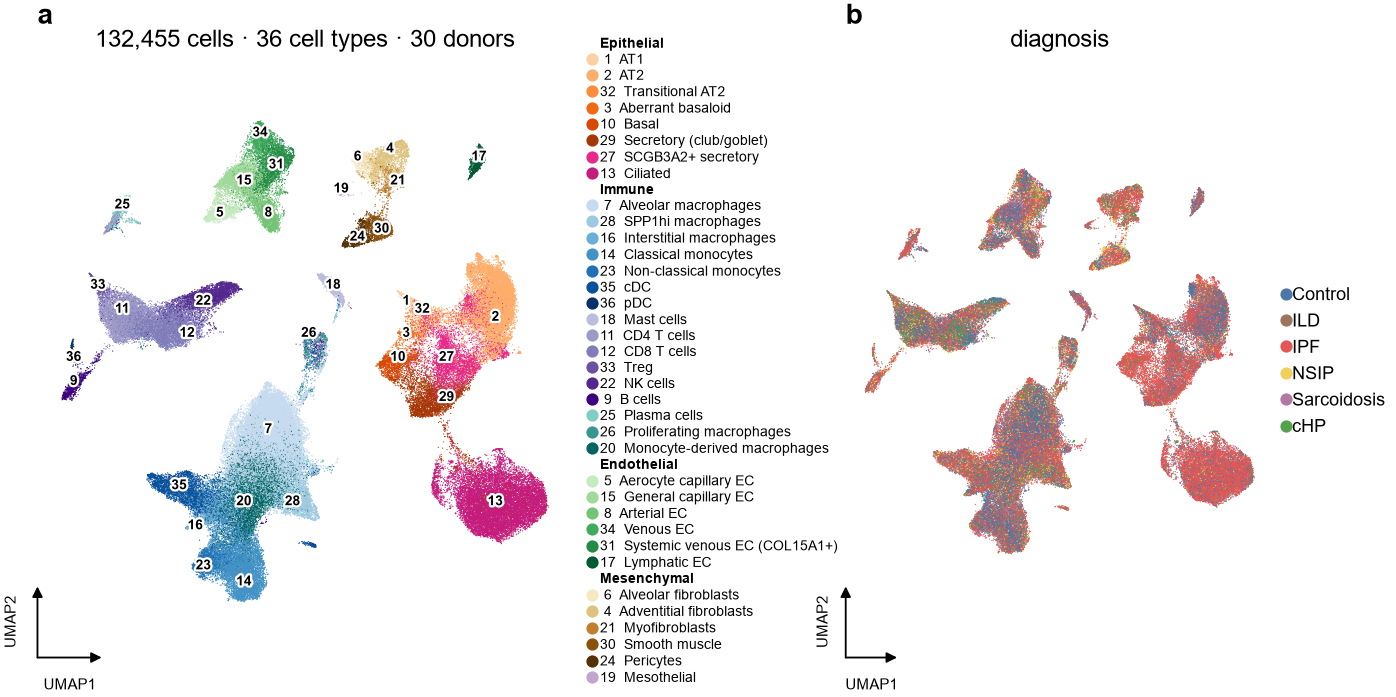

In [6]:
xy = adata.obsm["X_umap"]
fig = plt.figure(figsize=figsize(183, 90))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 0.6, 1.0], wspace=0.02)
ax_a, ax_key, ax_b = (fig.add_subplot(gs[i]) for i in range(3))
embedding_scatter(ax_a, xy, adata.obs["cell_type"], palette=pal, s=0.15)
numbers = label_centroids(ax_a, xy, adata.obs["cell_type"], fontsize=4.5, min_cells=1, numbered=True)
umap_axis_arrows(ax_a)
ax_a.set_title(f"{adata.n_obs:,} cells · {adata.obs.cell_type.nunique()} cell types · "
               f"{adata.obs.donor_id.nunique()} donors")
# key: numbered cell types grouped by compartment
handles = []
for comp_name in SECTIONS:
    handles.append(plt.Line2D([], [], ls="", label=comp_name))
    handles += [plt.Line2D([], [], marker="o", ls="", color=pal[t], markersize=3, label=f"{numbers[t]:>2}  {t}")
                for t in order if type_comp[t] == comp_name]
ax_key.axis("off")
key = ax_key.legend(handles=handles, loc="center left", frameon=False, fontsize=4.5, handletextpad=0.2,
                    labelspacing=0.22, handlelength=0.8, borderaxespad=0)
for txt in key.get_texts():
    if txt.get_text() in SECTIONS:
        txt.set_fontweight("bold")
embedding_scatter(ax_b, xy, adata.obs["diagnosis"], palette=CONDITION_COLORS, s=0.15, legend=True)
umap_axis_arrows(ax_b)
ax_b.set_title("diagnosis")
panel_label(ax_a, "a", x=0.0)
panel_label(ax_b, "b", x=0.0)
save_figure(fig, "Fig1_atlas_umap", FIG)
plt.show()

... storing 'celltypist' as categorical


... storing 'subcluster' as categorical


... storing 'cell_type_reason' as categorical


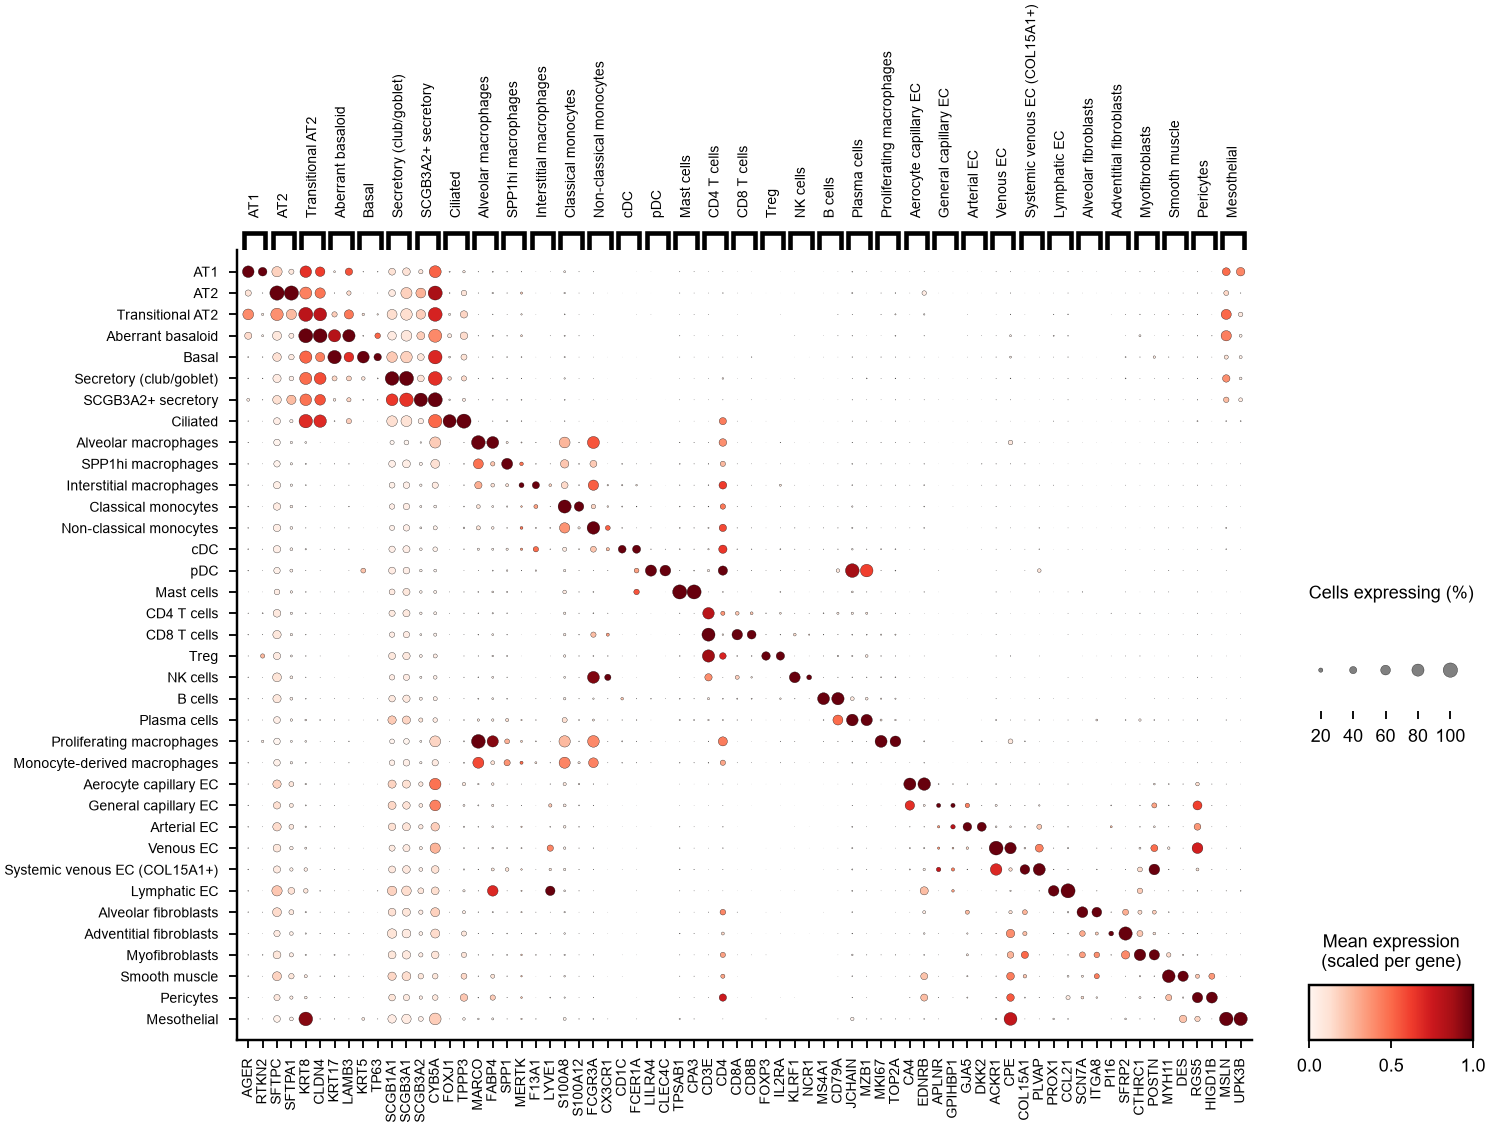

In [7]:
# two markers per type (sets list the most specific genes first), each gene shown once
EXTRA_GENES = {"Proliferating macrophages": ["MKI67", "TOP2A"]}
dot_genes, seen = {}, set()
for t in order:
    genes = markers[SECTIONS[type_comp[t]]].get(t, EXTRA_GENES.get(t, []))
    keep = [g for g in genes if g in adata.var_names and g not in seen][:2]
    seen.update(keep)
    if keep:
        dot_genes[t] = keep
dp = sc.pl.dotplot(adata, dot_genes, groupby="cell_type", standard_scale="var", dendrogram=False,
                   var_group_rotation=90, figsize=figsize(183, 120), return_fig=True)
dp.style(largest_dot=22, dot_edge_lw=0.1).legend(width=1.0, colorbar_title="Mean expression\n(scaled per gene)",
                                                 size_title="Cells expressing (%)")
dp.make_figure()
axd = dp.get_axes()
axd["mainplot_ax"].tick_params(labelsize=4.5)
for txt in axd["gene_group_ax"].texts:
    txt.set_fontsize(4.5)
save_figure(dp.fig, "Fig1_marker_dotplot", FIG)
plt.show()

## 6. Agreement with the original annotation
Our labels were derived independently from the authors' (different QC,
doublet calls, integration and marker sets). Agreement is measured on the
cells present in both, at the harmonised level shared with the authors'
label set where names differ.

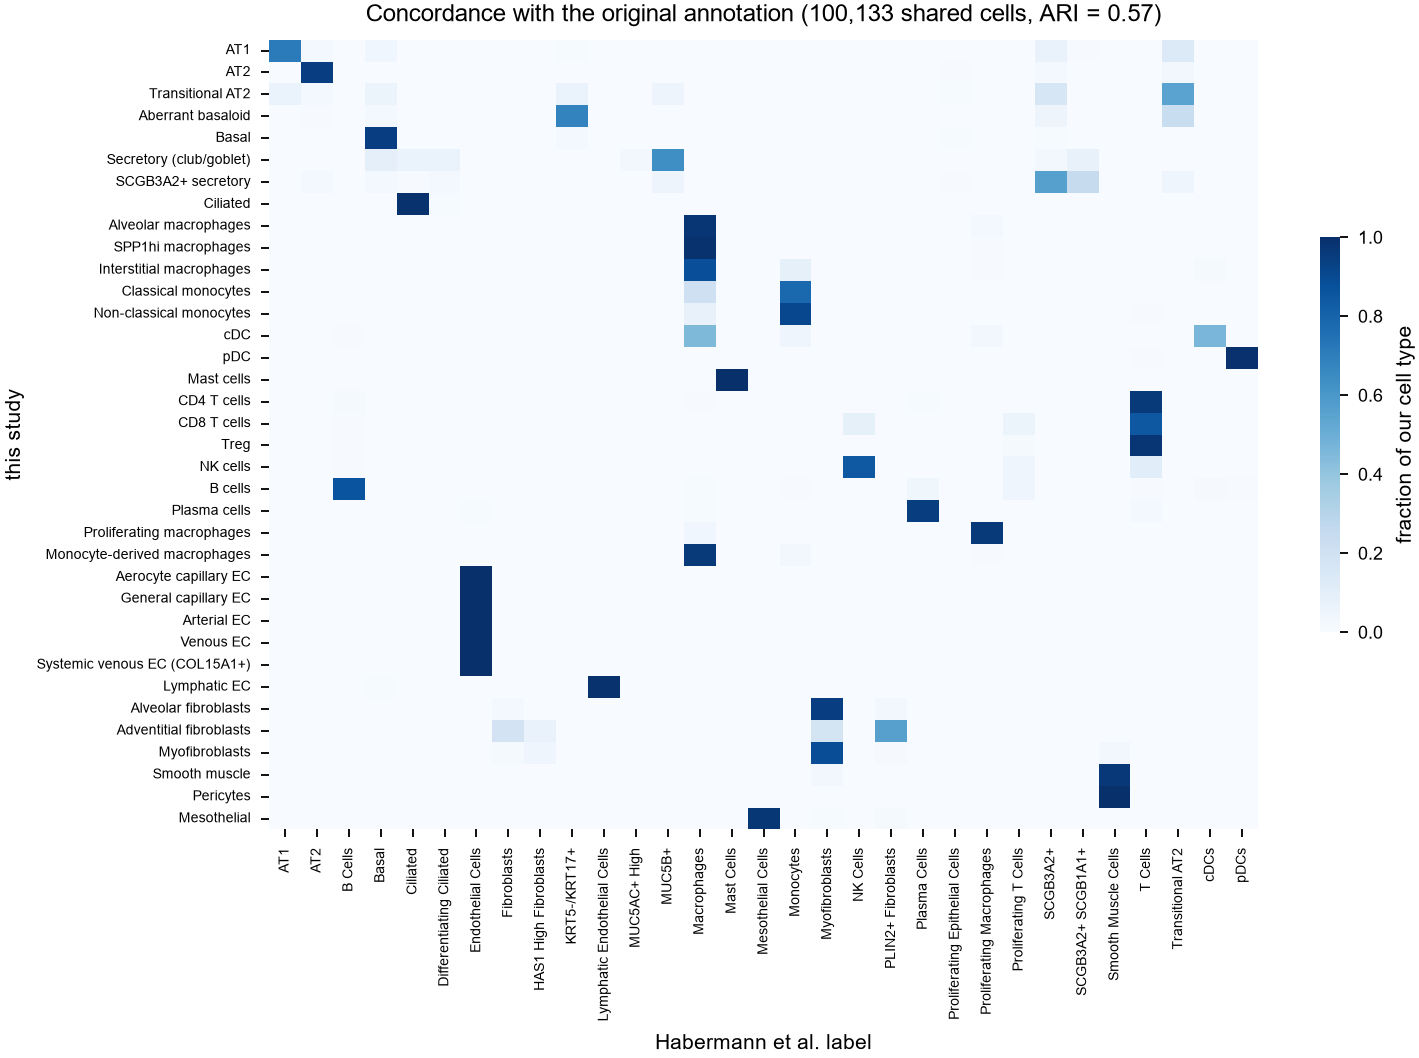

In [8]:
both = adata.obs["author_celltype"].notna()
ari = adjusted_rand_score(adata.obs.loc[both, "author_celltype"].astype(str), adata.obs.loc[both, "cell_type"].astype(str))
cm = pd.crosstab(adata.obs.loc[both, "cell_type"], adata.obs.loc[both, "author_celltype"], normalize="index")
write_table(cm.round(3), TAB / "concordance_with_authors")
fig, ax = plt.subplots(figsize=figsize(183, 120))
sns.heatmap(cm, cmap="Blues", vmin=0, vmax=1, ax=ax, xticklabels=True, yticklabels=True,
            cbar_kws={"label": "fraction of our cell type", "shrink": 0.5})
ax.tick_params(labelsize=4.5)
ax.set_xlabel("Habermann et al. label")
ax.set_ylabel("this study")
ax.set_title(f"Concordance with the original annotation ({both.sum():,} shared cells, ARI = {ari:.2f})")
save_figure(fig, "S5_concordance_with_authors", FIG)
plt.show()

In [9]:
summary = adata.obs.groupby(["compartment", "cell_type"], observed=True).agg(
    n_cells=("donor_id", "size"), n_donors=("donor_id", "nunique"),
    frac_IPF=("diagnosis", lambda x: (x == "IPF").mean()))
write_table(summary.round(3), TAB / "cell_type_summary")
for k in ["leiden_1.0", "compartment_l1"]:
    adata.obs[k] = adata.obs[k].astype("category")
adata.write_h5ad(P.processed / "discovery_annotated.h5ad", compression="lzf")
summary

n_cells  n_donors  frac_IPF
compartment cell_type                                                 
Endothelial Aerocyte capillary EC             1855        25  0.318059
            General capillary EC              3941        30  0.261101
            Arterial EC                       2290        30  0.402620
            Venous EC                         1916        30  0.360125
            Systemic venous EC (COL15A1+)     2830        30  0.493286
            Lymphatic EC                      1342        29  0.479136
Epithelial  AT1                               1489        30  0.333781
            AT2                              11233        29  0.389210
            Transitional AT2                   485        26  0.606186
            Aberrant basaloid                  482        21  0.721992
            Basal                             1636        24  0.848411
            Secretory (club/goblet)           3940        29  0.728173
            SCGB3A2+ secretory                5861        30  0.755673
            Ciliated                         13630        30  0.814674
Immune      Alveolar macrophages             21909        30  0.312931
            SPP1hi macrophages                4141        30  0.550833
            Interstitial macrophages          3830        30  0.394517
            Classical monocytes               8507        30  0.379805
            Non-classical monocytes           2203        30  0.359056
            cDC                               4807        30  0.523195
            pDC                                192        19  0.645833
            Mast cells                        1312        29  0.511433
            CD4 T cells                       5800        30  0.408793
            CD8 T cells                       6377        30  0.352360
            Treg                               814        26  0.528256
            NK cells                          3670        27  0.366485
            B cells                           1493        30  0.508372
            Plasma cells                       750        29  0.601333
            Proliferating macrophages          631        26  0.527734
            Monocyte-derived macrophages      7263        30  0.454220
Mesenchymal Alveolar fibroblasts               764        28  0.409686
            Adventitial fibroblasts           2197        28  0.715976
            Myofibroblasts                     688        30  0.515988
            Smooth muscle                     1132        29  0.544170
            Pericytes                          853        29  0.342321
            Mesothelial                        192        20  0.562500